In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [3]:
Plots.theme(:dao)

In [15]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [44]:
pal = cgrad(:tol_muted);
cpal = [pal[i] for i in 0.0:1/5:1]

In [6]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
read_data = filter(:nreads => !=(0), read_data)
# first split on classification
gd1 = groupby(read_data, :classification);

gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

classes = [gd_classes[i][1][!,:classification][2] for i in 1:length(gd_classes)]
classes = strip.(lowercase.(classes))
classes[10] = "marine hydrothermal vents"
classes[6] = "oral cavity"
classes[5] = "terrestrial soil"
classes[end] = "activated sludge"
classes;

Now need to pick an initial condition.

In [249]:
ind_choice = 2;
data = gd_classes[ind_choice];
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
small_to_large = sortperm(sizes);
ic_sys = sort(data[small_to_large[1]][!,:count],rev=true)

40-element Vector{Float64}:
 6.0
 4.0
 4.0
 3.0
 3.0
 2.0
 2.0
 2.0
 2.0
 2.0
 2.0
 1.0
 1.0
 ⋮
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0

In [250]:
# ic_sys = [1.0]

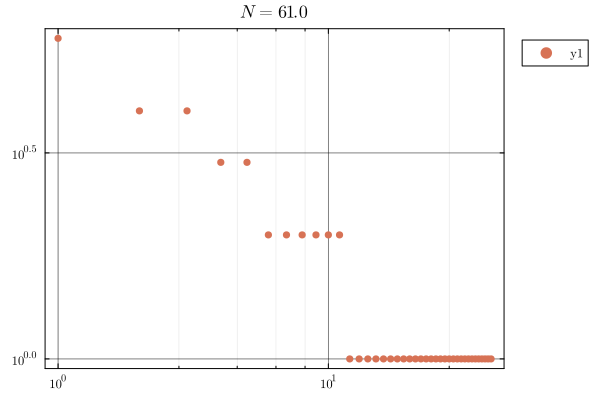

In [251]:
scatter(ic_sys, xaxis = :log10, yaxis = :log10, title = L"N=%$(sum(ic_sys))")

So for the initial condition we choose the smallest system in `oral`.

Now, we can explore different regimes of parameter space and the rank-frequency curves and abundance distributions that occur there.

Finally, let's take $p_0$ from `oral`.

In [254]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a
# p0_guess = 1

15.358610581101324

Points in the space.

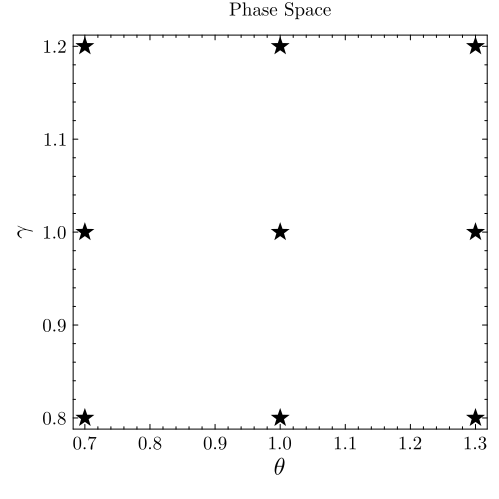

In [365]:
scatter([0.7,0.7,0.7,1,1,1,1.3,1.3,1.3], [1.2,1,0.8,1.2,1,0.8,1.2,1,0.8], color = :black, marker = :star5, markersize = 10, legend = :none)
plot!(grid = :none, minorgrid = :none, size = (500,500), title = "Phase Space")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 12)
plot!(xlabel = L"\theta", ylabel = L"\gamma")
# savefig("phase-space-conceptual.pdf")

# $\gamma = 1$, $\theta = 0$

In [255]:
sim1 = dsim.create_cell(0, 1, p0_guess, 10^5, ic_sys, :pdf);

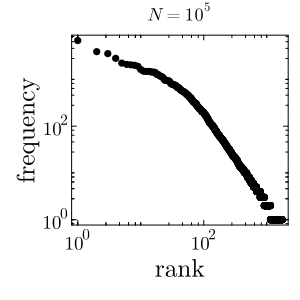

In [256]:
scatter(sim1, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)

In [257]:
sims1 = [dsim.create_cell(0, 1, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [258]:
sims1_n = [sims1[i]./sum(sims1[i]) for i in 1:length(sims1)];

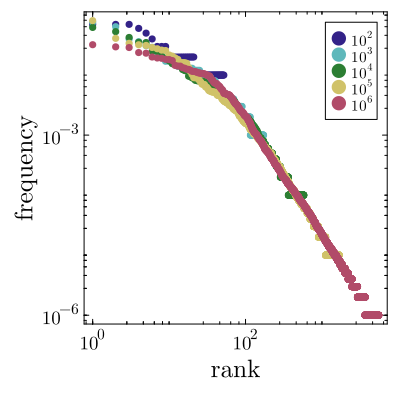

In [259]:
scatter(sims1_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims1_n)
    scatter!(sims1_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)

In [260]:
div1 = length.(sims1)

5-element Vector{Int64}:
   52
  172
  578
 1676
 5518

In [261]:
dglm1 = lm(@formula(y ~ x), DataFrame(y = log10.(div1), x = [2,3,4,5,6]))
coef1 = coef(dglm1)

2-element Vector{Float64}:
 0.7197821589186769
 0.5040302272403457

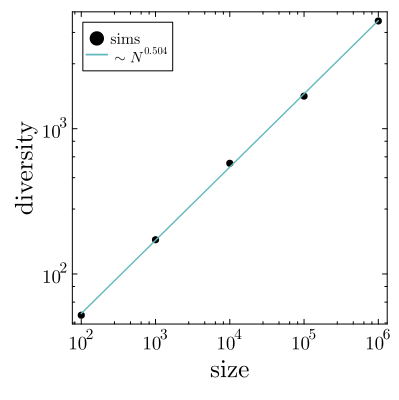

In [262]:
scatter(10 .^[2,3,4,5,6], div1, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef1[1] * 100^coef1[2], 10^coef1[1] * (10^6)^coef1[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef1[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

# $\gamma = 1$, $\theta = -5$

In [263]:
sim2 = dsim.create_cell(-5.0, 1, p0_guess, 10^5, ic_sys, :pdf);

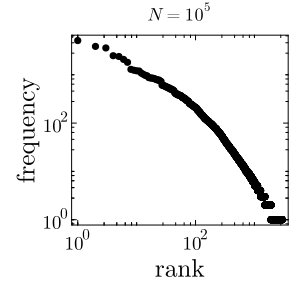

In [264]:
scatter(sim2, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)

In [265]:
sims2 = [dsim.create_cell(-5.0, 1, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [266]:
sims2_n = [sims2[i]./sum(sims2[i]) for i in 1:length(sims2)];

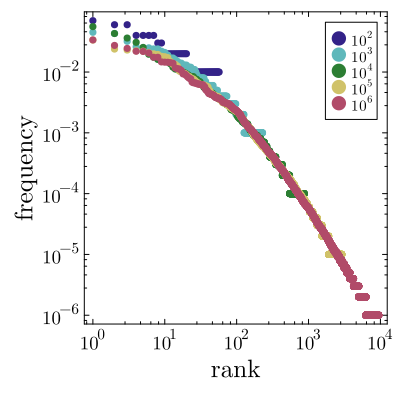

In [267]:
scatter(sims2_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims2_n)
    scatter!(sims2_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)

In [268]:
div2 = length.(sims2)

5-element Vector{Int64}:
   57
  229
  872
 2898
 9450

In [269]:
dglm2 = lm(@formula(y ~ x), DataFrame(y = log10.(div2), x = [2,3,4,5,6]))
coef2 = coef(dglm2)

2-element Vector{Float64}:
 0.6822006807303482
 0.5541376804468812

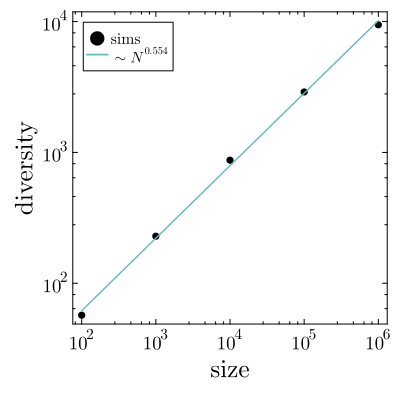

In [270]:
scatter(10 .^[2,3,4,5,6], div2, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef2[1] * 100^coef2[2], 10^coef2[1] * (10^6)^coef2[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef2[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

## Now, let's look at the required quadrants

# $\gamma = 1.2$, $\theta = 0.7$

In [271]:
sim3 = dsim.create_cell(0.7, 1.2, p0_guess, 10^5, ic_sys, :pdf);

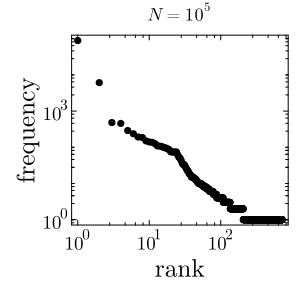

In [367]:
scatter(sim3, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-1.pdf")

In [410]:
CSV.write("./concept-fig/rf-1.csv", DataFrame(number = sim3))

"./concept-fig/rf-1.csv"

Regardless of the shape of the initial condition—starts to look power law over all ranks.

In [273]:
sims3 = [dsim.create_cell(0.7, 1.2, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [274]:
sims3_n = [sims3[i]./sum(sims3[i]) for i in 1:length(sims3)];

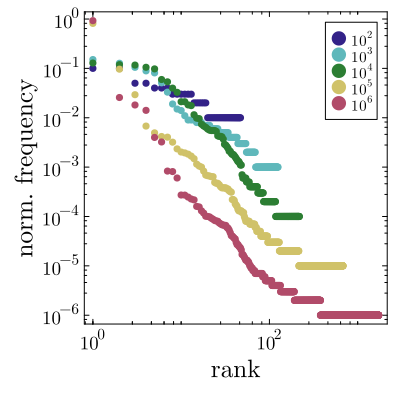

In [373]:
scatter(sims3_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims3_n)
    scatter!(sims3_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "norm. frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-all-1.pdf")

In [417]:
maxlen = maximum(length.(sims3_n))
padded = [vcat(v, fill(missing, maxlen - length(v))) for v in sims3_n]
df_pad = DataFrame(TenP2 = padded[1], TenP3 = padded[2], TenP4 = padded[3], TenP5 = padded[4], TenP6 = padded[5])
# CSV.write("./concept-fig/rf-all-1.csv", df_pad)

Row,TenP2,TenP3,TenP4,TenP5,TenP6
,Float64?,Float64?,Float64?,Float64?,Float64?
1,0.1,0.151,0.1284,0.81501,0.926605
2,0.1,0.127,0.1189,0.09637,0.025705
3,0.05,0.105,0.1167,0.02931,0.018133
4,0.05,0.089,0.1052,0.00678,0.014112
5,0.04,0.081,0.0976,0.00494,0.00399
6,0.04,0.051,0.0595,0.00417,0.00323
7,0.04,0.033,0.0534,0.00404,0.000831
8,0.03,0.019,0.0398,0.0032,0.000812
9,0.03,0.015,0.0327,0.00234,0.000602


Initial sense of universality fails for larger $N$.

In [276]:
div3 = length.(sims3)

5-element Vector{Int64}:
   47
  125
  218
  681
 1728

In [277]:
dglm3 = lm(@formula(y ~ x), DataFrame(y = log10.(div3), x = [2,3,4,5,6]))
coef3 = coef(dglm3)

2-element Vector{Float64}:
 0.8887794991931947
 0.3867128859319032

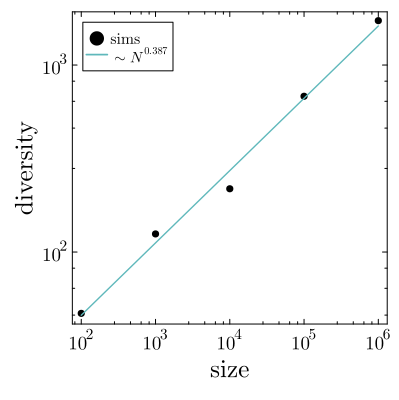

In [278]:
scatter(10 .^[2,3,4,5,6], div3, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef3[1] * 100^coef3[2], 10^coef3[1] * (10^6)^coef3[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef3[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

# $\gamma = 1$, $\theta = 0.7$

In [279]:
sim4 = dsim.create_cell(0.7, 1, p0_guess, 10^5, ic_sys, :pdf);

In [374]:
scatter(sim4, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-2.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/concept-fig/rf-2.pdf"

In [418]:
CSV.write("./concept-fig/rf-2.csv", DataFrame(number = sim4))

"./concept-fig/rf-2.csv"

Clear power-law tail, but with initial plateau.

In [281]:
sims4 = [dsim.create_cell(0.7, 1, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [282]:
sims4_n = [sims4[i]./sum(sims4[i]) for i in 1:length(sims4)];

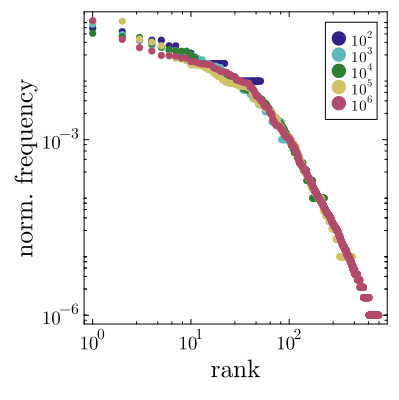

In [440]:
scatter(sims4_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims4_n)
    scatter!(sims4_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "norm. frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-all-2.pdf")

In [421]:
maxlen = maximum(length.(sims4_n))
padded = [vcat(v, fill(missing, maxlen - length(v))) for v in sims4_n]
df_pad = DataFrame(TenP2 = padded[1], TenP3 = padded[2], TenP4 = padded[3], TenP5 = padded[4], TenP6 = padded[5])
CSV.write("./concept-fig/rf-all-2.csv", df_pad)

"./concept-fig/rf-all-2.csv"

Universal RF curves.

In [284]:
div4 = length.(sims4)

5-element Vector{Int64}:
  51
 105
 227
 438
 813

In [285]:
dglm4 = lm(@formula(y ~ x), DataFrame(y = log10.(div4), x = [2,3,4,5,6]))
coef4 = coef(dglm4)

2-element Vector{Float64}:
 1.1171397775212621
 0.30253255504264265

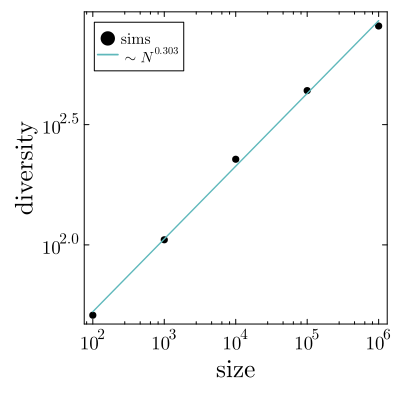

In [286]:
scatter(10 .^[2,3,4,5,6], div4, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef4[1] * 100^coef4[2], 10^coef4[1] * (10^6)^coef4[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef4[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

# $\gamma = 0.8$, $\theta = 0.7$

In [287]:
sim5 = dsim.create_cell(0.7, 0.8, p0_guess, 10^5, ic_sys, :pdf);

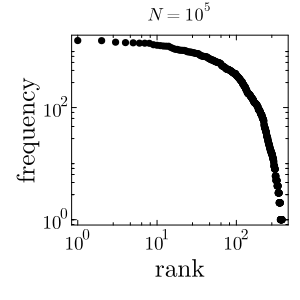

In [378]:
scatter(sim5, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-3.pdf")

In [422]:
CSV.write("./concept-fig/rf-3.csv", DataFrame(number = sim5))

"./concept-fig/rf-3.csv"

Clear power-law tail, but with initial plateau.

In [289]:
sims5 = [dsim.create_cell(0.7, 0.8, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [290]:
sims5_n = [sims5[i]./sum(sims5[i]) for i in 1:length(sims5)];

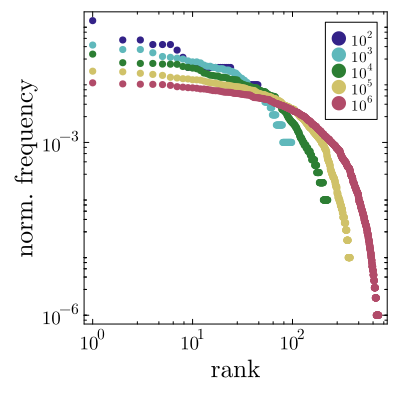

In [442]:
scatter(sims5_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims5_n)
    scatter!(sims5_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "norm. frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-all-3.pdf")

In [431]:
sm = sims5_n
maxlen = maximum(length.(sm))
padded = [vcat(v, fill(missing, maxlen - length(v))) for v in sm]
df_pad = DataFrame(TenP2 = padded[1], TenP3 = padded[2], TenP4 = padded[3], TenP5 = padded[4], TenP6 = padded[5])
CSV.write("./concept-fig/rf-all-3.csv", df_pad)

"./concept-fig/rf-all-3.csv"

In [292]:
div5 = length.(sims5)

5-element Vector{Int64}:
  45
  98
 225
 377
 728

In [293]:
dglm5 = lm(@formula(y ~ x), DataFrame(y = log10.(div5), x = [2,3,4,5,6]))
coef5 = coef(dglm5)

2-element Vector{Float64}:
 1.0858375651841308
 0.3002953005588688

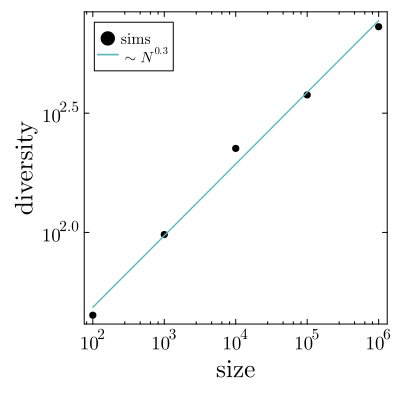

In [294]:
scatter(10 .^[2,3,4,5,6], div5, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef5[1] * 100^coef5[2], 10^coef5[1] * (10^6)^coef5[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef5[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

# $\gamma = 1.2$, $\theta = 1$

In [295]:
sim6 = dsim.create_cell(1, 1.2, p0_guess, 10^5, ic_sys, :pdf);

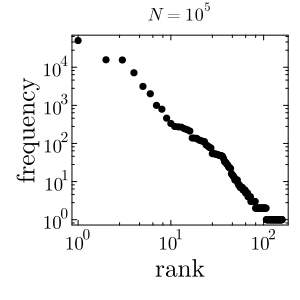

In [382]:
scatter(sim6, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-4.pdf")

In [423]:
CSV.write("./concept-fig/rf-4.csv", DataFrame(number = sim6))

"./concept-fig/rf-4.csv"

Clear power-law tail, but with initial plateau.

In [297]:
sims6 = [dsim.create_cell(1.0, 1.2, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [298]:
sims6_n = [sims6[i]./sum(sims6[i]) for i in 1:length(sims6)];

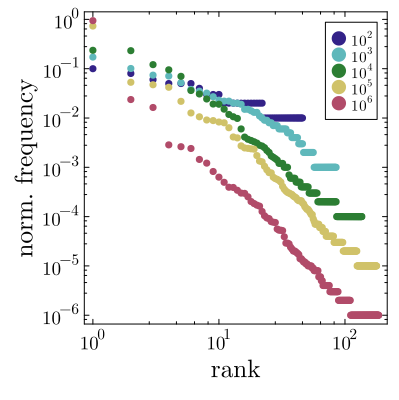

In [385]:
scatter(sims6_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims6_n)
    scatter!(sims6_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "norm. frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-all-4.pdf")

In [432]:
sm = sims6_n
maxlen = maximum(length.(sm))
padded = [vcat(v, fill(missing, maxlen - length(v))) for v in sm]
df_pad = DataFrame(TenP2 = padded[1], TenP3 = padded[2], TenP4 = padded[3], TenP5 = padded[4], TenP6 = padded[5])
CSV.write("./concept-fig/rf-all-4.csv", df_pad)

"./concept-fig/rf-all-4.csv"

In [300]:
div6 = length.(sims6)

5-element Vector{Int64}:
  46
  85
 136
 178
 185

In [301]:
dglm6 = lm(@formula(y ~ x), DataFrame(y = log10.(div6), x = [2,3,4,5,6]))
coef6 = coef(dglm6)

2-element Vector{Float64}:
 1.4367299312806037
 0.15298288700374862

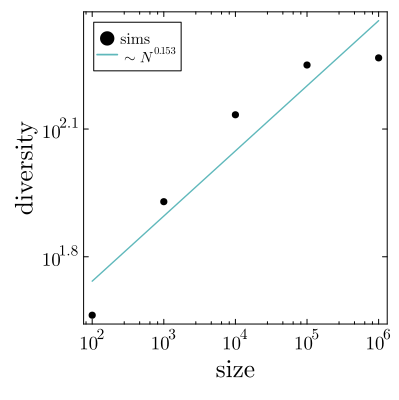

In [302]:
scatter(10 .^[2,3,4,5,6], div6, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef6[1] * 100^coef6[2], 10^coef6[1] * (10^6)^coef6[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef6[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

# $\gamma = 1$, $\theta = 1$

In [303]:
sim7 = dsim.create_cell(1, 1, p0_guess, 10^5, ic_sys, :pdf);

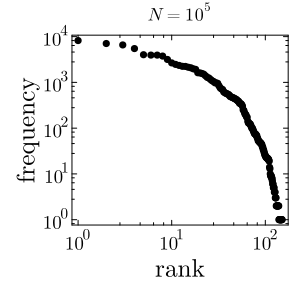

In [387]:
scatter(sim7, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-5.pdf")

In [424]:
CSV.write("./concept-fig/rf-5.csv", DataFrame(number = sim7))

"./concept-fig/rf-5.csv"

Clear power-law tail, but with initial plateau.

In [305]:
sims7 = [dsim.create_cell(1.0, 1, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [306]:
sims7_n = [sims7[i]./sum(sims7[i]) for i in 1:length(sims7)];

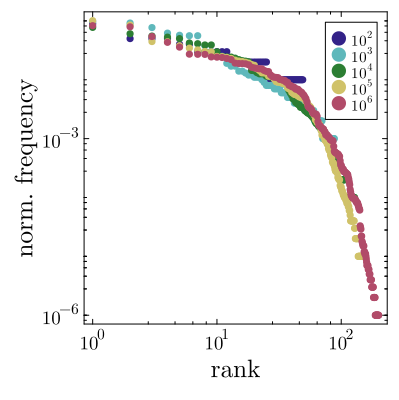

In [389]:
scatter(sims7_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims7_n)
    scatter!(sims7_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "norm. frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-all-5.pdf")

In [433]:
sm = sims7_n
maxlen = maximum(length.(sm))
padded = [vcat(v, fill(missing, maxlen - length(v))) for v in sm]
df_pad = DataFrame(TenP2 = padded[1], TenP3 = padded[2], TenP4 = padded[3], TenP5 = padded[4], TenP6 = padded[5])
CSV.write("./concept-fig/rf-all-5.csv", df_pad)

"./concept-fig/rf-all-5.csv"

In [308]:
div7 = length.(sims7)

5-element Vector{Int64}:
  49
  88
 128
 149
 200

In [309]:
dglm7 = lm(@formula(y ~ x), DataFrame(y = log10.(div7), x = [2,3,4,5,6]))
coef7 = coef(dglm7)

2-element Vector{Float64}:
 1.463072426167344
 0.14503714275330426

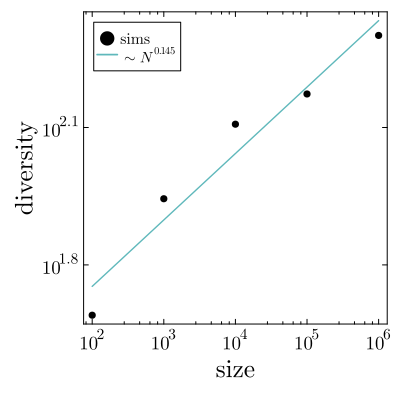

In [310]:
scatter(10 .^[2,3,4,5,6], div7, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef7[1] * 100^coef7[2], 10^coef7[1] * (10^6)^coef7[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef7[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

# $\gamma = 0.8$, $\theta = 1$

In [322]:
sim8 = dsim.create_cell(1, 0.8, p0_guess, 10^5, ic_sys, :pdf);

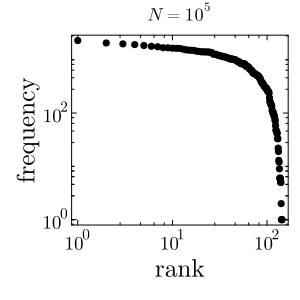

In [391]:
scatter(sim8, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-6.pdf")

In [425]:
CSV.write("./concept-fig/rf-6.csv", DataFrame(number = sim8))

"./concept-fig/rf-6.csv"

Clear power-law tail, but with initial plateau.

In [313]:
sims8 = [dsim.create_cell(1.0, 0.8, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [314]:
sims8_n = [sims8[i]./sum(sims8[i]) for i in 1:length(sims8)];

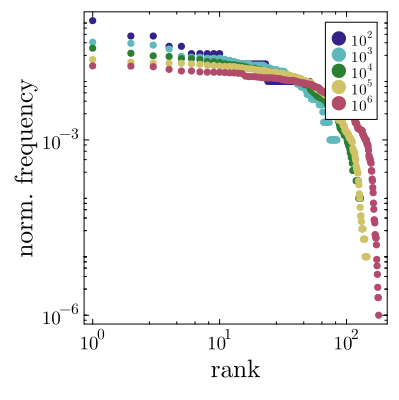

In [394]:
scatter(sims8_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims8_n)
    scatter!(sims8_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "norm. frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-all-6.pdf")

In [434]:
sm = sims8_n
maxlen = maximum(length.(sm))
padded = [vcat(v, fill(missing, maxlen - length(v))) for v in sm]
df_pad = DataFrame(TenP2 = padded[1], TenP3 = padded[2], TenP4 = padded[3], TenP5 = padded[4], TenP6 = padded[5])
CSV.write("./concept-fig/rf-all-6.csv", df_pad)

"./concept-fig/rf-all-6.csv"

In [316]:
div8 = length.(sims8)

5-element Vector{Int64}:
  51
  84
 129
 145
 179

In [317]:
dglm8 = lm(@formula(y ~ x), DataFrame(y = log10.(div8), x = [2,3,4,5,6]))
coef8 = coef(dglm8)

2-element Vector{Float64}:
 1.5002702707599818
 0.13276544259370118

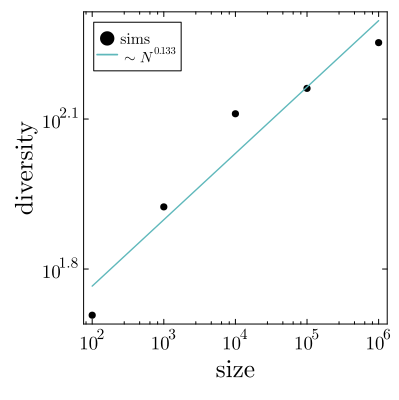

In [318]:
scatter(10 .^[2,3,4,5,6], div8, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef8[1] * 100^coef8[2], 10^coef8[1] * (10^6)^coef8[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef8[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

# $\gamma = 1.2$, $\theta = 1.3$

In [320]:
sim9 = dsim.create_cell(1.3, 1.2, p0_guess, 10^5, ic_sys, :pdf);

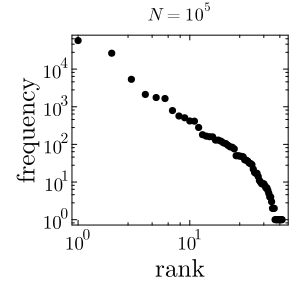

In [396]:
scatter(sim9, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-7.pdf")

In [426]:
CSV.write("./concept-fig/rf-7.csv", DataFrame(number = sim9))

"./concept-fig/rf-7.csv"

Clear power-law tail, but with initial plateau.

In [324]:
sims9 = [dsim.create_cell(1.3, 1.2, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [325]:
sims9_n = [sims9[i]./sum(sims9[i]) for i in 1:length(sims9)];

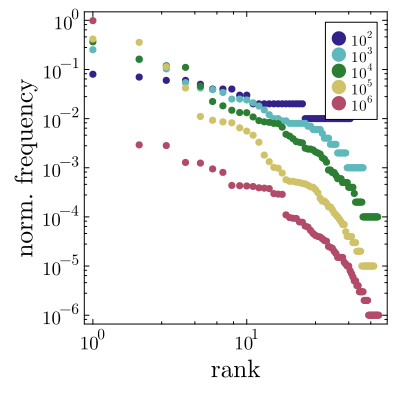

In [398]:
scatter(sims9_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims9_n)
    scatter!(sims9_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "norm. frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-all-7.pdf")

In [435]:
sm = sims9_n
maxlen = maximum(length.(sm))
padded = [vcat(v, fill(missing, maxlen - length(v))) for v in sm]
df_pad = DataFrame(TenP2 = padded[1], TenP3 = padded[2], TenP4 = padded[3], TenP5 = padded[4], TenP6 = padded[5])
CSV.write("./concept-fig/rf-all-7.csv", df_pad)

"./concept-fig/rf-all-7.csv"

In [327]:
div9 = length.(sims9)

5-element Vector{Int64}:
 47
 57
 71
 67
 72

In [328]:
dglm9 = lm(@formula(y ~ x), DataFrame(y = log10.(div9), x = [2,3,4,5,6]))
coef9 = coef(dglm9)

2-element Vector{Float64}:
 1.6162599826841015
 0.04406692240194359

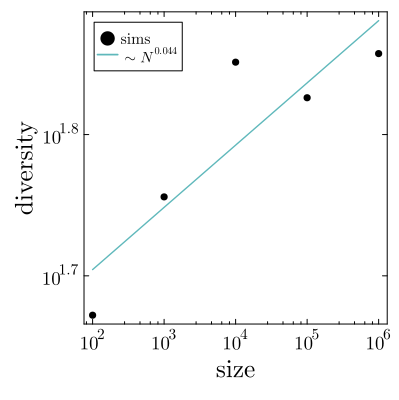

In [329]:
scatter(10 .^[2,3,4,5,6], div9, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef9[1] * 100^coef9[2], 10^coef9[1] * (10^6)^coef9[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef9[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

# $\gamma = 1$, $\theta = 1.3$

In [330]:
sim10 = dsim.create_cell(1.3, 1, p0_guess, 10^5, ic_sys, :pdf);

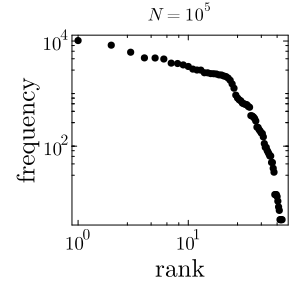

In [401]:
scatter(sim10, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-8.pdf")

In [427]:
CSV.write("./concept-fig/rf-8.csv", DataFrame(number = sim10))

"./concept-fig/rf-8.csv"

Clear power-law tail, but with initial plateau.

In [338]:
sims10 = [dsim.create_cell(1.3, 1, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [339]:
sims10_n = [sims10[i]./sum(sims10[i]) for i in 1:length(sims10)];

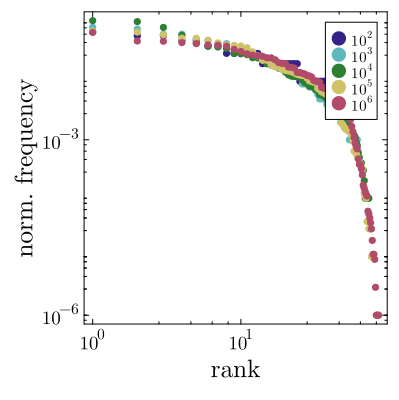

In [404]:
scatter(sims10_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims10_n)
    scatter!(sims10_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "norm. frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-all-8.pdf")

In [436]:
sm = sims10_n
maxlen = maximum(length.(sm))
padded = [vcat(v, fill(missing, maxlen - length(v))) for v in sm]
df_pad = DataFrame(TenP2 = padded[1], TenP3 = padded[2], TenP4 = padded[3], TenP5 = padded[4], TenP6 = padded[5])
CSV.write("./concept-fig/rf-all-8.csv", df_pad)

"./concept-fig/rf-all-8.csv"

In [341]:
div10 = length.(sims10)

5-element Vector{Int64}:
 47
 61
 73
 76
 85

In [342]:
dglm10 = lm(@formula(y ~ x), DataFrame(y = log10.(div10), x = [2,3,4,5,6]))
coef10 = coef(dglm10)

2-element Vector{Float64}:
 1.5821462570815354
 0.061012589282717355

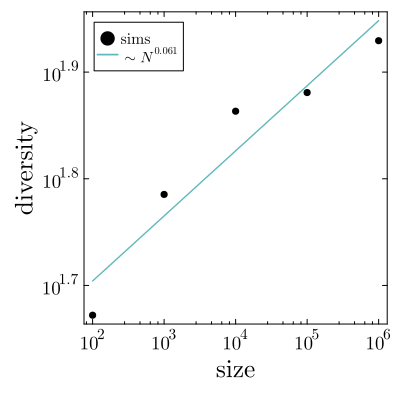

In [343]:
scatter(10 .^[2,3,4,5,6], div10, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef10[1] * 100^coef10[2], 10^coef10[1] * (10^6)^coef10[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef10[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)

# $\gamma = 0.8$, $\theta = 1.3$

In [344]:
sim11 = dsim.create_cell(1.3, 0.8, p0_guess, 10^5, ic_sys, :pdf);

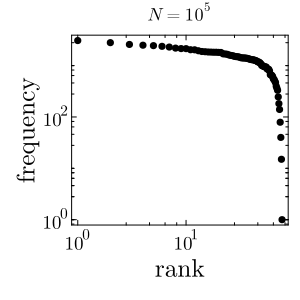

In [406]:
scatter(sim11, xaxis = :log10, yaxis = :log10, color = :black, label = :none)
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N = 10^5")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-9.pdf")

In [428]:
CSV.write("./concept-fig/rf-9.csv", DataFrame(number = sim11))

"./concept-fig/rf-9.csv"

Clear power-law tail, but with initial plateau.

In [346]:
sims11 = [dsim.create_cell(1.3, 0.8, p0_guess, 10^x, ic_sys, :pdf) for x in [2,3,4,5,6]];

In [347]:
sims11_n = [sims11[i]./sum(sims11[i]) for i in 1:length(sims11)];

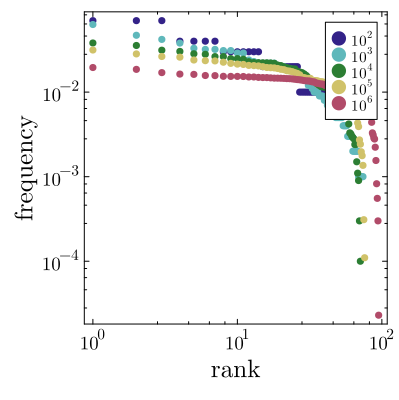

In [408]:
scatter(sims11_n[1], xaxis = :log10, yaxis = :log10, color = cpal[1], label = L"10^2")
for i in 2:length(sims11_n)
    scatter!(sims11_n[i], color = cpal[i], label = L"10^%$(i+1)")
end
plot!(xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12)
# savefig("./concept-fig/rf-all-9.pdf")

In [437]:
sm = sims11_n
maxlen = maximum(length.(sm))
padded = [vcat(v, fill(missing, maxlen - length(v))) for v in sm]
df_pad = DataFrame(TenP2 = padded[1], TenP3 = padded[2], TenP4 = padded[3], TenP5 = padded[4], TenP6 = padded[5])
CSV.write("./concept-fig/rf-all-9.csv", df_pad)

"./concept-fig/rf-all-9.csv"

In [349]:
div11 = length.(sims11)

5-element Vector{Int64}:
 44
 74
 71
 76
 95

In [350]:
dglm11 = lm(@formula(y ~ x), DataFrame(y = log10.(div11), x = [2,3,4,5,6]))
coef11 = coef(dglm11)

2-element Vector{Float64}:
 1.572446496439121
 0.06801237301551366

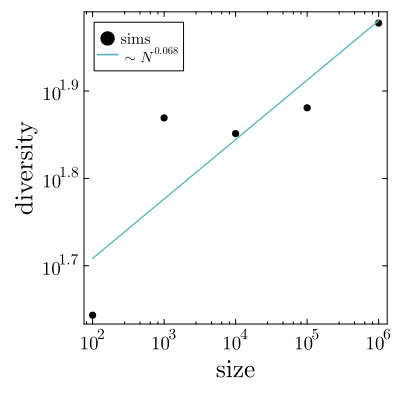

In [351]:
scatter(10 .^[2,3,4,5,6], div11, xaxis = :log10, yaxis = :log10, color = :black, label = "sims")
plot!([100,10^6], [10^coef11[1] * 100^coef11[2], 10^coef11[1] * (10^6)^coef11[2]], color = cpal[2], label = L"$\sim N^{%$(round(coef11[2], digits = 3))}$")
plot!(xlabel = "size", ylabel = "diversity", grid = false, minorgrid = false, alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (400,400), legend = :topright)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, legendposition = :topleft)